# S8 - Procesamiento en streaming con Spark: ventanas, watermarking y semantica de entrega
**Proyecto Sello · Equipo 10 BIG IMPACT · Salcca Aquino, Nilver**

**Actividad:** construir un pipeline de Spark Structured Streaming sobre `heladas-eventos` (el mismo topic de Kafka que S7 ya deja publicando lecturas reales de clima de WeatherAPI para Juliaca), aplicando agregaciones por ventana de tiempo, watermarking para datos tardios, checkpointing para tolerancia a fallos, deduplicacion acotada, y comparando semantica de entrega y throughput/latencia bajo distintos parametros.

## 3.2 Crear el notebook y la `SparkSession`, con el conector de Kafka

**Producto del paso:** notebook `08_streaming_estructurado_practica.ipynb` con una `SparkSession` capaz de leer y escribir Kafka.

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion8-streaming-estructurado")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f655fb59-1347-497b-ab97-0f7477fa1776;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

`spark.jars.packages` agrega el conector `spark-sql-kafka-0-10`, que Spark no trae por defecto (a diferencia de la lectura de CSV o Parquet de S2-S4). La primera vez que se ejecuta esta celda, Spark descarga el conector y sus dependencias desde Maven Central, puede tardar. `spark.sql.shuffle.partitions` se baja a 3 (pensado para las 3 particiones del topic, S7; si tu topic quedo con menos particiones, como una sola, no pasa nada, Spark igual funciona): con el valor por defecto (200), cada micro-lote crearia 200 tareas para casi ningun dato.

Verifica que el topic tiene mensajes, con una lectura **batch** (no streaming), el mismo tipo de lectura que ya usaste con CSV o Parquet, aplicada a Kafka:

## 3.2 Crear el notebook y la `SparkSession`, con el conector de Kafka

In [3]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion8-streaming-estructurado")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

### 3.2.b Verificar que el topic tiene mensajes (lectura batch)

In [4]:
lote = (
    spark.read.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "heladas-eventos")
    .option("startingOffsets", "earliest")
    .load()
)
print("mensajes en el topic:", lote.count())
lote.selectExpr("CAST(key AS STRING) AS key", "CAST(value AS STRING) AS value", "partition", "offset").orderBy("offset", ascending=False).show(3, truncate=False)

mensajes en el topic: 186
+-------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------+------+
|key    |value                                                                                                                                                                                                        |partition|offset|
+-------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------+------+
|Juliaca|{"tipoEvento": "clima.lectura", "ciudad": "Juliaca", "temperatura": 9.2, "puntoRocio": 5.6, "humedad": 79, "nubosidad": 64, "origen": "weatherapi", "observadoEn": 1795147200000, "timestamp": 1795147405343}|1        |185   |
|Juliaca|{"tipoEvento": "clima.lectura", "

### 3.2.c Gráfico: mensajes por partición y temperatura registrada en el topic


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


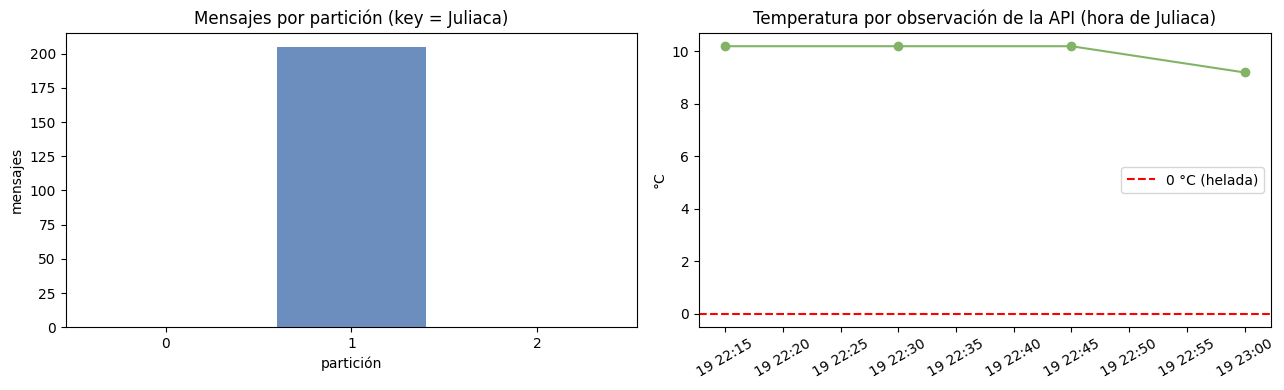

In [5]:
try:
    import matplotlib
except ImportError:
    %pip install -q matplotlib
    import matplotlib

import json
import pandas as pd
import matplotlib.pyplot as plt

pdf = lote.selectExpr("CAST(value AS STRING) AS value", "partition").toPandas()
pdf = pdf[pdf["value"].str.startswith("{")]          # ignora mensajes que no son JSON
datos = pd.json_normalize(pdf["value"].apply(json.loads))
datos["partition"] = pdf["partition"].values
datos = datos[datos["temperatura"].between(-30, 40)]  # mismo rango físico del consumer

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Izquierda: mensajes por partición
por_particion = datos["partition"].value_counts().reindex([0, 1, 2], fill_value=0)
axs[0].bar(por_particion.index.astype(str), por_particion.values, color="#6c8ebf")
axs[0].set_title("Mensajes por partición (key = Juliaca)")
axs[0].set_xlabel("partición")
axs[0].set_ylabel("mensajes")

# Derecha: una lectura por cada observación distinta de la API
obs = datos.drop_duplicates("observadoEn").sort_values("observadoEn")
hora = pd.to_datetime(obs["observadoEn"], unit="ms") - pd.Timedelta(hours=5)
axs[1].plot(hora, obs["temperatura"], marker="o", color="#82b366")
axs[1].axhline(0, color="red", ls="--", label="0 °C (helada)")
axs[1].set_title("Temperatura por observación de la API (hora de Juliaca)")
axs[1].set_ylabel("°C")
axs[1].legend()
axs[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 3.3 Leer el topic en modo streaming

In [6]:
crudo = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "heladas-eventos")
    .option("startingOffsets", "latest")
    .load()
)
print("es un stream:", crudo.isStreaming)
crudo.printSchema()

es un stream: True
root
 |-- key: binary (nullable = true)
 |-- value: binary (nullable = true)
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- timestampType: integer (nullable = true)



## 3.4 Parsear el JSON con un esquema explícito

In [7]:
from pyspark.sql.functions import from_json, col
from pyspark.sql.types import StructType, StringType, DoubleType, LongType

esquema_evento = (
    StructType()
    .add("tipoEvento", StringType())
    .add("ciudad", StringType())
    .add("temperatura", DoubleType())
    .add("puntoRocio", DoubleType())
    .add("humedad", DoubleType())
    .add("nubosidad", DoubleType())
    .add("origen", StringType())
    .add("observadoEn", LongType())
    .add("timestamp", LongType())
)

eventos = (
    crudo.selectExpr("CAST(value AS STRING) AS json_str")
    .select(from_json(col("json_str"), esquema_evento).alias("e"))
    .select("e.*")
    .withColumn("ts", (col("timestamp") / 1000).cast("timestamp"))
)
eventos.printSchema()

root
 |-- tipoEvento: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: double (nullable = true)
 |-- nubosidad: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- observadoEn: long (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- ts: timestamp (nullable = true)



## 5. Primera consulta: ver los eventos llegar

In [8]:
# Momento 1: arrancar la consulta
consulta = (
    eventos.writeStream
    .outputMode("append")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="5 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+----------+------+-----------+----------+-------+---------+------+-----------+---------+---+
|tipoEvento|ciudad|temperatura|puntoRocio|humedad|nubosidad|origen|observadoEn|timestamp|ts |
+----------+------+-----------+----------+-------+---------+------+-----------+---------+---+
+----------+------+-----------+----------+-------+---------+------+-----------+---------+---+



-------------------------------------------
Batch: 1
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |ts                     |
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|clima.lectura|Juliaca|9.2        |5.6       |79.0   |64.0     |weatherapi|1795147200000|1795147622871|2026-11-20 04:07:02.871|
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+

-------------------------------------------
Batch: 2
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|tipoEvento   |ciudad |temperatura|pu

In [9]:
# Lista las consultas de streaming que están corriendo ahora mismo
for q in spark.streams.active:
    print(q.id, "|", q.name, "|", q.isActive)
print("total activas:", len(spark.streams.active))

222a8893-4953-4b98-9283-6c54c5cbf9d4 | None | True
total activas: 1
-------------------------------------------
Batch: 48
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+----------------------+
|tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |ts                    |
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+----------------------+
|clima.lectura|Juliaca|9.2        |5.6       |79.0   |64.0     |weatherapi|1795147200000|1795147857640|2026-11-20 04:10:57.64|
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+----------------------+

-------------------------------------------
Batch: 49
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-----------

## 6. Escribir la salida a Parquet, con checkpoint

In [10]:
ARTIFACTS = "./artifacts/heladas_parquet"
CHECKPOINT_PARQUET = "./artifacts/chk_parquet"

consulta2 = (
    eventos.writeStream
    .outputMode("append")
    .format("parquet")
    .option("path", ARTIFACTS)
    .option("checkpointLocation", CHECKPOINT_PARQUET)
    .trigger(processingTime="5 seconds")
    .start()
)
print("consulta2 activa:", consulta2.isActive)

consulta2 activa: True
-------------------------------------------
Batch: 89
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |ts                     |
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|clima.lectura|Juliaca|9.2        |5.6       |79.0   |64.0     |weatherapi|1795147200000|1795148060581|2026-11-20 04:14:20.581|
|clima.lectura|Juliaca|9.2        |5.6       |79.0   |64.0     |weatherapi|1795147200000|1795148063992|2026-11-20 04:14:23.992|
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+

-------------------------------------------
Batch: 90
-------------------------------------------
+-----------

### 6.1 Leer lo que se guardó en Parquet

In [11]:
print("consultas activas:", len(spark.streams.active))

guardado = spark.read.parquet(ARTIFACTS)
print("filas guardadas:", guardado.count())
guardado.select("ciudad", "temperatura", "puntoRocio", "ts").orderBy("ts").show(10, truncate=False)

consultas activas: 2
filas guardadas: 6
+-------+-----------+----------+-----------------------+
|ciudad |temperatura|puntoRocio|ts                     |
+-------+-----------+----------+-----------------------+
|Juliaca|9.2        |5.6       |2026-11-20 04:14:27.497|
|Juliaca|9.2        |5.6       |2026-11-20 04:14:30.886|
|Juliaca|9.2        |5.6       |2026-11-20 04:14:34.276|
|Juliaca|9.2        |5.6       |2026-11-20 04:14:37.568|
|Juliaca|9.2        |5.6       |2026-11-20 04:14:40.955|
|Juliaca|9.2        |5.6       |2026-11-20 04:14:44.325|
+-------+-----------+----------+-----------------------+

-------------------------------------------
Batch: 94
-------------------------------------------
+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-----------------------+
|tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |ts                     |
+-------------+-------+-----------+

### 6.2 Detener las consultas

In [12]:
consulta.stop()
consulta2.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 7. Ventana de tiempo sin límite (modo complete)

In [13]:
from pyspark.sql.functions import window, count

agregado = (
    eventos
    .groupBy(window(col("ts"), "10 seconds"), col("ciudad"))
    .agg(count("*").alias("n"))
)

consulta_ventana = (
    agregado.writeStream
    .outputMode("complete")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="5 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+------+------+---+
|window|ciudad|n  |
+------+------+---+
+------+------+---+



-------------------------------------------
Batch: 1
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:15:40, 2026-11-20 04:15:50}|Juliaca|2  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 2
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:15:40, 2026-11-20 04:15:50}|Juliaca|3  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 3
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+----------------------

### 7.1 Detener la consulta de ventanas

In [14]:
consulta_ventana.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 8. Watermark: hasta cuándo esperar eventos tardíos

In [15]:
agregado_wm = (
    eventos
    .withWatermark("ts", "10 seconds")
    .groupBy(window(col("ts"), "10 seconds"), col("ciudad"))
    .agg(count("*").alias("n"))
)

consulta_wm = (
    agregado_wm.writeStream
    .outputMode("update")
    .format("console")
    .option("truncate", "false")
    .option("checkpointLocation", "/tmp/s08-chk-watermark")
    .trigger(processingTime="5 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+------+------+---+
|window|ciudad|n  |
+------+------+---+
+------+------+---+

-------------------------------------------
Batch: 1
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:17:10, 2026-11-20 04:17:20}|Juliaca|1  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 2
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:17:10, 2026-11-20 04:17:20}|Juliaca|2  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 3
---

### 8.1 Detener la consulta con watermark

In [16]:
consulta_wm.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 9. Ventana deslizante

In [17]:
agregado_desl = (
    eventos
    .withWatermark("ts", "10 seconds")
    .groupBy(window(col("ts"), "10 seconds", "5 seconds"), col("ciudad"))
    .agg(count("*").alias("n"))
)

consulta_desl = (
    agregado_desl.writeStream
    .outputMode("update")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="5 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+------+------+---+
|window|ciudad|n  |
+------+------+---+
+------+------+---+



-------------------------------------------
Batch: 1
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:18:20, 2026-11-20 04:18:30}|Juliaca|1  |
|{2026-11-20 04:18:15, 2026-11-20 04:18:25}|Juliaca|1  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 2
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:18:25, 2026-11-20 04:18:35}|Juliaca|2  |
|{2026-11-20 04:18:20, 2026-11-20 04:18:30}|Juliaca|3  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 3
-------------------------------------------
+----------------------

### 9.1 Detener la consulta deslizante

In [18]:
consulta_desl.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 10. Checkpointing: qué guarda Spark en disco

In [19]:
import os

for ruta in ["/tmp/s08-chk-watermark", "./artifacts/chk_parquet"]:
    print("====", ruta)
    for carpeta, _, archivos in os.walk(ruta):
        nivel = carpeta.replace(ruta, "").count(os.sep)
        print("  " * nivel + os.path.basename(carpeta) + "/", "->", len(archivos), "archivo(s)")

==== /tmp/s08-chk-watermark
s08-chk-watermark/ -> 2 archivo(s)
  state/ -> 0 archivo(s)
    0/ -> 0 archivo(s)
      _metadata/ -> 2 archivo(s)
      1/ -> 24 archivo(s)
      0/ -> 24 archivo(s)
        _metadata/ -> 2 archivo(s)
      2/ -> 24 archivo(s)
  offsets/ -> 22 archivo(s)
  commits/ -> 22 archivo(s)
  sources/ -> 0 archivo(s)
    0/ -> 2 archivo(s)
==== ./artifacts/chk_parquet
chk_parquet/ -> 2 archivo(s)
  commits/ -> 22 archivo(s)
  offsets/ -> 22 archivo(s)
  sources/ -> 0 archivo(s)
    0/ -> 2 archivo(s)


### 10.1 Leer el último offset anotado

In [21]:
carpeta = "./artifacts/chk_parquet/offsets"
numericos = [f for f in os.listdir(carpeta) if f.isdigit()]
ultimo = max(numericos, key=int)
print("último archivo de offsets:", ultimo)
print("-----")
print(open(os.path.join(carpeta, ultimo)).read())

último archivo de offsets: 10
-----
v1
{"batchWatermarkMs":0,"batchTimestampMs":1795148115005,"conf":{"spark.sql.streaming.stateStore.providerClass":"org.apache.spark.sql.execution.streaming.state.HDFSBackedStateStoreProvider","spark.sql.streaming.stateStore.rocksdb.mergeOperatorVersion":"2","spark.sql.streaming.stateStore.rocksdb.formatVersion":"5","spark.sql.streaming.queryEvolution.enableSourceEvolution":"false","spark.sql.streaming.stateStore.encodingFormat":"unsaferow","spark.sql.streaming.statefulOperator.useStrictDistribution":"true","spark.sql.streaming.flatMapGroupsWithState.stateFormatVersion":"2","spark.sql.streaming.multipleWatermarkPolicy":"min","spark.sql.streaming.stateStore.rowChecksum.enabled":"false","spark.sql.streaming.aggregation.stateFormatVersion":"2","spark.sql.function.protobufExtensions.enabled":"false","spark.sql.shuffle.partitions":"3","spark.sql.streaming.join.stateFormatVersion":"2","spark.sql.streaming.stateStore.compression.codec":"lz4","spark.sql.optimi

## 11. Dato tardío: qué pasa con un evento que llega muy atrasado

In [22]:
import threading
import time
from pyspark.sql.functions import to_json, struct

def publicar_evento_tardio(segundos_de_espera, segundos_en_el_pasado):
    time.sleep(segundos_de_espera)
    ahora_ms = int(time.time() * 1000)
    marca_vieja = ahora_ms - segundos_en_el_pasado * 1000
    columnas = ["tipoEvento", "ciudad", "temperatura", "puntoRocio", "humedad",
                "nubosidad", "origen", "observadoEn", "timestamp"]
    evento_tardio = [("clima.lectura", "juliaca-tardio", 99.9, 50.0, 50.0, 50.0,
                      "prueba-watermark", marca_vieja, marca_vieja)]
    df_tardio = spark.createDataFrame(evento_tardio, columnas)
    salida = df_tardio.select(
        df_tardio.ciudad.cast("string").alias("key"),
        to_json(struct(*columnas)).alias("value"),
    )
    (salida.write.format("kafka")
        .option("kafka.bootstrap.servers", "kafka:9092")
        .option("topic", "heladas-eventos")
        .save())
    print(f">>> publicado juliaca-tardio, {segundos_en_el_pasado}s en el pasado")

hilo = threading.Thread(target=publicar_evento_tardio, args=(15, 45), daemon=True)
hilo.start()

agregado_tardio = (
    eventos
    .withWatermark("ts", "5 seconds")
    .groupBy(window(col("ts"), "10 seconds"), col("ciudad"))
    .agg(count("*").alias("n"))
)

consulta_tardio = (
    agregado_tardio.writeStream
    .outputMode("update")
    .format("console")
    .option("truncate", "false")
    .option("checkpointLocation", "/tmp/s08-chk-tardio")
    .trigger(processingTime="4 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+------+------+---+
|window|ciudad|n  |
+------+------+---+
+------+------+---+

-------------------------------------------
Batch: 1
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:00, 2026-11-20 04:21:10}|Juliaca|1  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 2
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:10, 2026-11-20 04:21:20}|Juliaca|1  |
+------------------------------------------+-------+---+



-------------------------------------------
Batch: 3
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:10, 2026-11-20 04:21:20}|Juliaca|3  |
+------------------------------------------+-------+---+



>>> publicado juliaca-tardio, 45s en el pasado
-------------------------------------------
Batch: 4
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:20, 2026-11-20 04:21:30}|Juliaca|1  |
+------------------------------------------+-------+---+



-------------------------------------------
Batch: 5
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:20, 2026-11-20 04:21:30}|Juliaca|2  |
+------------------------------------------+-------+---+



-------------------------------------------
Batch: 6
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:30, 2026-11-20 04:21:40}|Juliaca|1  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 7
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:30, 2026-11-20 04:21:40}|Juliaca|2  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 8
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+----------------------

-------------------------------------------
Batch: 11
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:50, 2026-11-20 04:22:00}|Juliaca|1  |
+------------------------------------------+-------+---+



-------------------------------------------
Batch: 12
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:50, 2026-11-20 04:22:00}|Juliaca|2  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 13
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:21:50, 2026-11-20 04:22:00}|Juliaca|3  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 14
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+-------------------

-------------------------------------------
Batch: 21
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:22:30, 2026-11-20 04:22:40}|Juliaca|1  |
+------------------------------------------+-------+---+



-------------------------------------------
Batch: 22
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:22:30, 2026-11-20 04:22:40}|Juliaca|2  |
+------------------------------------------+-------+---+

-------------------------------------------
Batch: 23
-------------------------------------------
+------------------------------------------+-------+---+
|window                                    |ciudad |n  |
+------------------------------------------+-------+---+
|{2026-11-20 04:22:30, 2026-11-20 04:22:40}|Juliaca|3  |
+------------------------------------------+-------+---+



### 11.1 Detener la consulta del dato tardío

In [23]:
consulta_tardio.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 12. Deduplicación: eliminar eventos repetidos

In [24]:
# Momento 1: consulta que descarta duplicados
sin_duplicados = (
    eventos
    .withWatermark("ts", "30 seconds")
    .dropDuplicates(["ciudad", "timestamp"])
    .select("ciudad", "temperatura", "timestamp", "ts")
)

consulta_dedup = (
    sin_duplicados.writeStream
    .outputMode("append")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="4 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+------+-----------+---------+---+
|ciudad|temperatura|timestamp|ts |
+------+-----------+---------+---+
+------+-----------+---------+---+

-------------------------------------------
Batch: 1
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148589041|2026-11-20 04:23:09.041|
+-------+-----------+-------------+-----------------------+

-------------------------------------------
Batch: 2
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148592523|2026-11-20 04:23:12.523|
+-------+-----------+------

In [25]:
# Momento 2: publicar el evento duplicado
time.sleep(6)
columnas = ["tipoEvento", "ciudad", "temperatura", "puntoRocio", "humedad",
            "nubosidad", "origen", "observadoEn", "timestamp"]
ahora_ms = int(time.time() * 1000)
evento_duplicado = spark.createDataFrame(
    [("clima.lectura", "juliaca-duplicado", 55.0, 55.0, 55.0, 55.0,
      "prueba-dedup", ahora_ms, ahora_ms)],
    columnas,
)
salida = evento_duplicado.select(
    evento_duplicado.ciudad.cast("string").alias("key"),
    to_json(struct(*columnas)).alias("value"),
)
for intento in range(2):
    (salida.write.format("kafka")
        .option("kafka.bootstrap.servers", "kafka:9092")
        .option("topic", "heladas-eventos")
        .save())
print(">>> 'juliaca-duplicado' publicado DOS veces")


-------------------------------------------
Batch: 8
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148618327|2026-11-20 04:23:38.327|
+-------+-----------+-------------+-----------------------+

-------------------------------------------
Batch: 9
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148622011|2026-11-20 04:23:42.011|
+-------+-----------+-------------+-----------------------+



>>> 'juliaca-duplicado' publicado DOS veces
-------------------------------------------
Batch: 10
-------------------------------------------
+-----------------+-----------+-------------+-----------------------+
|ciudad           |temperatura|timestamp    |ts                     |
+-----------------+-----------+-------------+-----------------------+
|juliaca-duplicado|55.0       |1795148626136|2026-11-20 04:23:46.136|
|Juliaca          |9.2        |1795148625426|2026-11-20 04:23:45.426|
+-----------------+-----------+-------------+-----------------------+



-------------------------------------------
Batch: 11
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148628881|2026-11-20 04:23:48.881|
+-------+-----------+-------------+-----------------------+

-------------------------------------------
Batch: 12
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts                     |
+-------+-----------+-------------+-----------------------+
|Juliaca|9.2        |1795148632764|2026-11-20 04:23:52.764|
+-------+-----------+-------------+-----------------------+

-------------------------------------------
Batch: 13
-------------------------------------------
+-------+-----------+-------------+-----------------------+
|ciudad |temperatura|timestamp    |ts       

### 12.1 Detener la consulta de deduplicación

In [27]:
consulta_dedup.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 13. Intervalo de disparo (trigger): cada cuánto procesa Spark

In [28]:
def probar_trigger(intervalo, duracion=20):
    q = (
        eventos.writeStream
        .outputMode("append")
        .format("noop")
        .trigger(processingTime=intervalo)
        .start()
    )
    time.sleep(duracion)
    progreso = q.recentProgress
    q.stop()
    tandas = [p for p in progreso if p["numInputRows"] > 0]
    filas = sum(p["numInputRows"] for p in tandas)
    print(f"trigger {intervalo:>10} | tandas con datos: {len(tandas)} | filas leídas: {filas}")
    return tandas

t1 = probar_trigger("1 seconds")
t6 = probar_trigger("6 seconds")

trigger  1 seconds | tandas con datos: 6 | filas leídas: 6
trigger  6 seconds | tandas con datos: 3 | filas leídas: 5


## 14. Hallazgos y conclusiones

| Concepto | Qué observé en mi corrida |
|---|---|
| Ventana sin límite (`complete`) | Cada tanda reimprimía todas las ventanas desde el inicio (5 ventanas en el Batch 9). El estado crece sin límite. |
| Watermark (`update`) | Con 10 s de margen, cada tanda mostró solo la ventana que cambió y Spark descartó el estado de las ventanas cerradas. |
| Ventana deslizante | Con ventana de 10 s y salto de 5 s, cada evento contó en dos ventanas traslapadas. |
| Checkpoint | `offsets` y `commits` guardan una entrada por tanda; el último offset leído de la partición 1 fue 397. Al reiniciar, la consulta continúa desde ahí. |
| Dato tardío | `juliaca-tardio` (45 s en el pasado, watermark de 5 s) fue descartado: nunca apareció en una ventana. |
| Deduplicación | `juliaca-duplicado` se publicó dos veces con la misma ciudad y `timestamp`, y salió una sola vez. |
| Trigger | 1 s: 6 tandas de 1 fila. 6 s: 3 tandas de 1 a 2 filas. Menor intervalo da menor latencia pero más tandas. |

**Conclusión:** para el proyecto de heladas, el watermark y la deduplicación evitan que el estado crezca sin límite y que una lectura repetida de la API cuente dos veces; el checkpoint permite reiniciar sin perder eventos.

## 15. Demostrar que los datos llegan en tiempo real

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

mensajes de Juliaca en el topic: 661
último evento llegó hace 0.9 segundos
la API midió esa temperatura hace 15.4 minutos


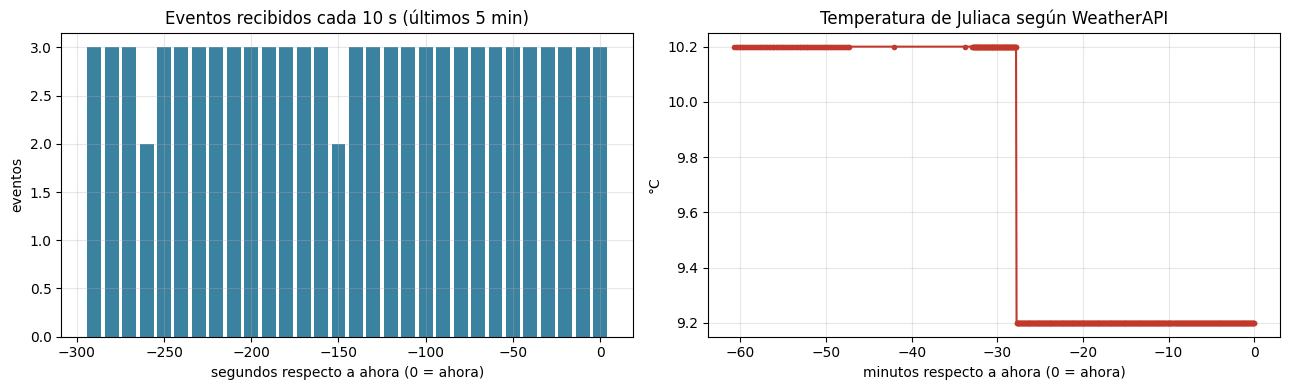

In [29]:
import time
import pandas as pd
import matplotlib.pyplot as plt

lote_vivo = (
    spark.read.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "heladas-eventos")
    .option("startingOffsets", "earliest")
    .load()
)

pdf = (
    lote_vivo.selectExpr("CAST(value AS STRING) AS json_str")
    .select(from_json(col("json_str"), esquema_evento).alias("e"))
    .select("e.*")
    .toPandas()
)
pdf = pdf[pdf["ciudad"] == "Juliaca"].copy()

ahora = time.time()
pdf["seg_atras"] = ahora - pdf["timestamp"] / 1000
pdf["min_atras"] = pdf["seg_atras"] / 60
pdf["obs_min_atras"] = (ahora - pdf["observadoEn"] / 1000) / 60

print("mensajes de Juliaca en el topic:", len(pdf))
print(f"último evento llegó hace {pdf['seg_atras'].min():.1f} segundos")
print(f"la API midió esa temperatura hace {pdf['obs_min_atras'].min():.1f} minutos")

# Gráfico 1: llegadas por bloque de 10 s en los últimos 5 minutos
reciente = pdf[pdf["seg_atras"] <= 300].copy()
reciente["bloque"] = -(reciente["seg_atras"] // 10) * 10
llegadas = reciente.groupby("bloque").size()

# Gráfico 2: temperatura reportada en el tiempo
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

ejes[0].bar(llegadas.index, llegadas.values, width=8, color="#3b82a0")
ejes[0].set_title("Eventos recibidos cada 10 s (últimos 5 min)")
ejes[0].set_xlabel("segundos respecto a ahora (0 = ahora)")
ejes[0].set_ylabel("eventos")

ejes[1].plot(-pdf["min_atras"], pdf["temperatura"], color="#c0392b", marker=".", linestyle="-")
ejes[1].set_title("Temperatura de Juliaca según WeatherAPI")
ejes[1].set_xlabel("minutos respecto a ahora (0 = ahora)")
ejes[1].set_ylabel("°C")

for e in ejes:
    e.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Demostrar que Spark jala de Kafka en vivo

In [31]:
vista_kafka = crudo.select(
    col("topic"),
    col("partition"),
    col("offset"),
    col("timestamp").alias("kafka_timestamp"),
    col("value").cast("string").alias("mensaje_json"),
)

consulta_kafka = (
    vista_kafka.writeStream
    .outputMode("append")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="3 seconds")
    .start()
)

consulta_kafka.awaitTermination(20)
consulta_kafka.stop()

-------------------------------------------
Batch: 0
-------------------------------------------
+-----+---------+------+---------------+------------+
|topic|partition|offset|kafka_timestamp|mensaje_json|
+-----+---------+------+---------------+------------+
+-----+---------+------+---------------+------------+

-------------------------------------------
Batch: 1
-------------------------------------------
+---------------+---------+------+----------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|topic          |partition|offset|kafka_timestamp       |mensaje_json                                                                                                                                                                                                 |
+---------------+---------+------+----------------------+----

## 17. Parquet en una segunda corrida: acumula, no sobreescribe

filas antes: 15 | filas después: 365 | se agregaron: 350


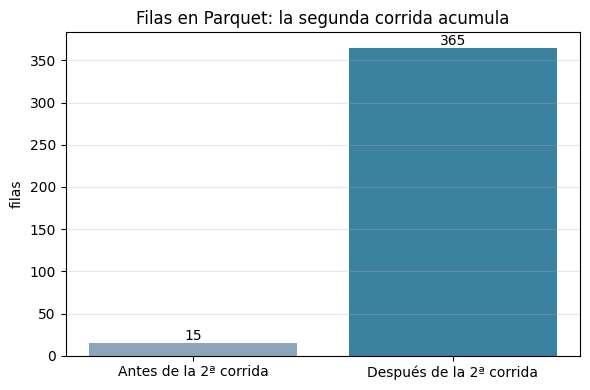

In [32]:
import matplotlib.pyplot as plt

antes = spark.read.parquet(ARTIFACTS).count()

# Misma consulta del paso 6, mismo path y mismo checkpoint
consulta3 = (
    eventos.writeStream
    .outputMode("append")
    .format("parquet")
    .option("path", ARTIFACTS)
    .option("checkpointLocation", CHECKPOINT_PARQUET)
    .trigger(processingTime="5 seconds")
    .start()
)
consulta3.awaitTermination(25)
consulta3.stop()

despues = spark.read.parquet(ARTIFACTS).count()
print("filas antes:", antes, "| filas después:", despues, "| se agregaron:", despues - antes)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Antes de la 2ª corrida", "Después de la 2ª corrida"], [antes, despues], color=["#8aa6b8", "#3b82a0"])
for i, v in enumerate([antes, despues]):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Filas en Parquet: la segunda corrida acumula")
ax.set_ylabel("filas")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 18. Intervalo de disparo medido con batchId

Con disparo cada 1 segundo, último batchId en 15 s: 4
Con disparo cada 6 segundos, último batchId en 15 s: 3


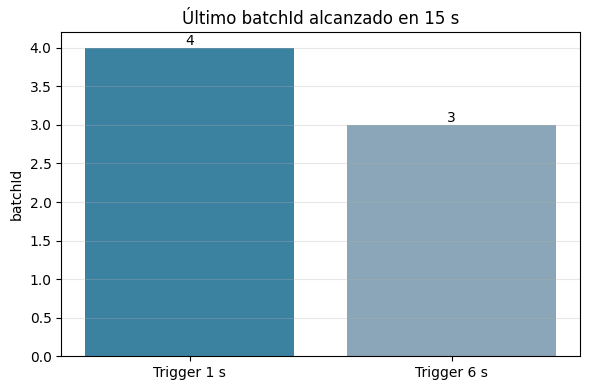

In [33]:
def contar_microlotes(intervalo, segundos_totales):
    q = (
        eventos.writeStream
        .outputMode("append")
        .format("memory")
        .queryName(f"conteo_{intervalo.replace(' ', '_')}")
        .trigger(processingTime=intervalo)
        .start()
    )
    q.awaitTermination(segundos_totales)
    q.stop()
    return q.lastProgress["batchId"] if q.lastProgress else None

lote_rapido = contar_microlotes("1 second", 15)
lote_lento = contar_microlotes("6 seconds", 15)

print("Con disparo cada 1 segundo, último batchId en 15 s:", lote_rapido)
print("Con disparo cada 6 segundos, último batchId en 15 s:", lote_lento)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Trigger 1 s", "Trigger 6 s"], [lote_rapido, lote_lento], color=["#3b82a0", "#8aa6b8"])
for i, v in enumerate([lote_rapido, lote_lento]):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Último batchId alcanzado en 15 s")
ax.set_ylabel("batchId")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
for q in spark.streams.active:
    q.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0
